## Process wikipedia data files

World record performances are here on [Wikipedia](https://en.wikipedia.org/wiki/List_of_world_records_in_athletics#Men)

Convert to CSV using [this webpage](https://wikitable2csv.ggor.de/) and process here.

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [18]:
mens_IAAF = pd.read_csv("data/mens-IAAF-records.csv")
mens_IAAF.head()

,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,V,P
0,100 m,9.58,+0.9,NaN,Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[5],​,P
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P


In [19]:
mens_IAAF.tail()

,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,V,P
46,4×400 m relay,2:54.29,NaN,NaN,Andrew ValmonQuincy WattsButch ReynoldsMichael...,USA,22 Aug 1993,World Championships,Stuttgart,GER,[g] [31],​,P
47,4×800 m relay,7:02.43,NaN,NaN,Joseph MutuaWilliam YiampoyIsmael KombichWilfr...,KEN,25 Aug 2006,Memorial Van Damme,Brussels,BEL,NaN,​,NaN
48,Distance medley relay,9:15.50,NaN,[h],Kyle MerberBrycen SpratlingBrandon JohnsonBen ...,USA,3 May 2015,World Relays,Nassau,BAH,[32],NaN,NaN
49,4×1500 m relay,14:22.22,NaN,NaN,Collins CheboiSilas KiplagatJames Kiplagat Mag...,KEN,25 May 2014,World Relays,Nassau,BAH,[33],​,NaN
50,Road relay42.195 km,1:57:06.00,NaN,[i],Josephat NdambiriMartin MathathiDaniel Muchunu...,KEN,23 Nov 2005,Chiba Ekiden,Chiba,JPN,NaN,NaN,NaN


In [13]:
mens_IAAF_indoor = pd.read_csv("data/mens-IAAF-indoor-records.csv")
mens_IAAF_indoor.head()

,Event,Perf.,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,V,P
0,50 m,5.55,X[q],Ben Johnson,CAN,31 Jan 1987,NaN,Ottawa,CAN,[59],NaN,NaN
1,50 m,5.56,A,Donovan Bailey,CAN,9 Feb 1996,Bill Cosby Invitational,Reno,USA,NaN,​,NaN
2,50 m,5.56,#[r],Maurice Greene,USA,13 Feb 1999,NaN,Los Angeles,USA,[60],NaN,NaN
3,60 m,6.34,A,Christian Coleman,USA,18 Feb 2018,USA Championships,Albuquerque,USA,[61],​,P
4,200 m,19.92,NaN,Frankie Fredericks,NAM,18 Feb 1996,Meeting Pas de Calais,Liévin,FRA,NaN,​,NaN


In [14]:
mens_nonIAAF = pd.read_csv("data/mens-nonIAAF-records.csv")
mens_nonIAAF.head()

,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,P
0,50 m,5.40,+0.2,+[ac],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84],NaN
1,60 m,6.25,+0.2,+[ad],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84][85],NaN
2,60 m,6.31,+0.9,+[ae],Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[86],NaN
3,100 y,9.00,NaN,h,Ivory Crockett,USA,11 May 1974,NaN,Knoxville,USA,[87],NaN
4,100 y,9.00,NaN,h,Houston McTear,USA,9 May 1975,NaN,Winter Park,USA,[87],NaN


We're only concerned about running events

In [16]:
mens_IAAF.iloc[:23, :]

,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,V,P
0,100 m,9.58,+0.9,NaN,Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[5],​,P
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P
5,1500 m,3:26.00,NaN,NaN,Hicham El Guerrouj,MAR,14 Jul 1998,Golden Gala,Rome,ITA,NaN,​,P
6,Mile,3:43.13,NaN,NaN,Hicham El Guerrouj,MAR,7 Jul 1999,Golden Gala,Rome,ITA,NaN,​,P
7,2000 m,4:44.79,NaN,NaN,Hicham El Guerrouj,MAR,7 Sep 1999,ISTAF,Berlin,GER,NaN,​,NaN
8,3000 m,7:20.67,NaN,NaN,Daniel Komen,KEN,1 Sep 1996,Rieti Meeting,Rieti,ITA,NaN,​,P
9,5000 m (track),12:37.35,NaN,NaN,Kenenisa Bekele,ETH,31 May 2004,Fanny Blankers-Koen Games,Hengelo,NED,NaN,​,P


## Manually tag distance, parse other fields

In [20]:
mens_IAAF_running = mens_IAAF.iloc[:23, :]
mens_IAAF_running["distance"] = [100, 200, 400, 800,
                                 1000, 1500, 1609, 2000,
                                 3000, 5000, 5000, 5000, 10000,
                                 10000, 10000, 20000, 21000,
                                 21285, 25000, 30000, 42000, 42000, 100000]

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


In [22]:
mens_nonIAAF_running = mens_nonIAAF.iloc[:28, :]
mens_nonIAAF_running["distance"] = [50, 60, 60, 100*0.9144, 100*0.9144, 100*0.9144, 150, 150, 200, 220*0.9144, 220*0.9144, 300, 440*0.9144, 500, 600, 1609*2, 5000, 8000, 15000, 10*1609, 20000, 25000, 30000, 35000, 40000, 50000, 90000, 100000]
mens_nonIAAF_running.head()

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,P,distance
0,50 m,5.40,+0.2,+[ac],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84],NaN,50.00
1,60 m,6.25,+0.2,+[ad],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84][85],NaN,60.00
2,60 m,6.31,+0.9,+[ae],Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[86],NaN,60.00
3,100 y,9.00,NaN,h,Ivory Crockett,USA,11 May 1974,NaN,Knoxville,USA,[87],NaN,91.44
4,100 y,9.00,NaN,h,Houston McTear,USA,9 May 1975,NaN,Winter Park,USA,[87],NaN,91.44


In [23]:
def parse_time(x):
    spl = x.split(":")
    if len(spl) == 1:
        try:
            return float(x)
        except ValueError: 
            return None
    elif len(spl) == 2:
        return float(spl[0])*60+float(spl[1])
    elif len(spl) == 3:
        return float(spl[0])*60*60+float(spl[1])*60+float(spl[2])
    else:
        print("unrecognized: "+x)
    return None
mens_IAAF_running["seconds"] = mens_IAAF_running["Perf."].apply(parse_time)
mens_nonIAAF_running["seconds"] = mens_nonIAAF_running["Perf."].apply(parse_time)

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  from ipykernel import kernelapp as app
/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  app.launch_new_instance()


In [24]:
mens_IAAF_running["seconds"].fillna(3600, inplace=True)

/usr/local/lib/python3.6/site-packages/pandas/core/generic.py:5434: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  self._update_inplace(new_data)


In [25]:
mens_IAAF_running["pace"] = mens_IAAF_running.distance/mens_IAAF_running.seconds
mens_nonIAAF_running["pace"] = mens_nonIAAF_running.distance/mens_nonIAAF_running.seconds

/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.
/usr/local/lib/python3.6/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  


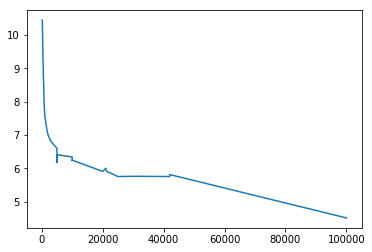

In [27]:
plt.plot(mens_IAAF_running.distance, mens_IAAF_running.pace)

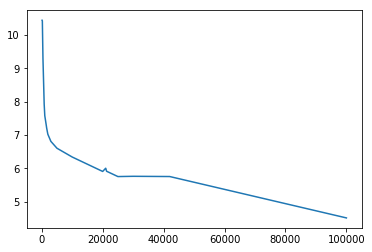

In [28]:
mens_IAAF_running_dedup = mens_IAAF_running.drop_duplicates(["distance"], 'first')
plt.plot(mens_IAAF_running_dedup.distance, mens_IAAF_running_dedup.pace)

## Combine all of the records (IAAF and non)

In [29]:
mens_running_all = pd.concat([mens_IAAF_running, mens_nonIAAF_running], sort=False)
mens_running_all

,Event,Perf.,W,N,Athlete(s),Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace
0,100 m,9.58,+0.9,NaN,Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[5],​,P,100.000,9.58,10.438413
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P,200.000,19.19,10.422095
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P,400.000,43.03,9.295840
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P,800.000,100.91,7.927857
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P,1000.000,131.96,7.578054
5,1500 m,3:26.00,NaN,NaN,Hicham El Guerrouj,MAR,14 Jul 1998,Golden Gala,Rome,ITA,NaN,​,P,1500.000,206.00,7.281553
6,Mile,3:43.13,NaN,NaN,Hicham El Guerrouj,MAR,7 Jul 1999,Golden Gala,Rome,ITA,NaN,​,P,1609.000,223.13,7.211043
7,2000 m,4:44.79,NaN,NaN,Hicham El Guerrouj,MAR,7 Sep 1999,ISTAF,Berlin,GER,NaN,​,NaN,2000.000,284.79,7.022718
8,3000 m,7:20.67,NaN,NaN,Daniel Komen,KEN,1 Sep 1996,Rieti Meeting,Rieti,ITA,NaN,​,P,3000.000,440.67,6.807815
9,5000 m (track),12:37.35,NaN,NaN,Kenenisa Bekele,ETH,31 May 2004,Fanny Blankers-Koen Games,Hengelo,NED,NaN,​,P,5000.000,757.35,6.601967


In [32]:
mens_running_all_dedup = mens_running_all.sort_values(["distance", "seconds"]).drop_duplicates(["distance"], 'first')

mens_running_all_dedup["logpace"] = np.log10(mens_running_all_dedup.pace)
mens_running_all_dedup["logdistance"] = np.log10(mens_running_all_dedup.distance)
mens_running_all_dedup["time"] = mens_running_all_dedup.seconds/60
mens_running_all_dedup["logtime"] = np.log10(mens_running_all_dedup.time)
mens_running_all_dedup.columns = list(map(lambda x: x.strip(), mens_running_all_dedup.columns))
mens_running_all_dedup.rename(columns={"Athlete(s)": "Athlete", "Perf.": "Perf"}, inplace=True)

mens_running_all_dedup

,Event,Perf,W,N,Athlete,Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace,logpace,logdistance,time,logtime
0,50 m,5.40,+0.2,+[ac],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84],NaN,NaN,50.000,5.40,9.259259,0.966576,1.698970,0.090000,-1.045757
1,60 m,6.25,+0.2,+[ad],Bruny Surin,CAN,22 Aug 1999,World Championships,Seville,ESP,[84][85],NaN,NaN,60.000,6.25,9.600000,0.982271,1.778151,0.104167,-0.982271
3,100 y,9.00,NaN,h,Ivory Crockett,USA,11 May 1974,NaN,Knoxville,USA,[87],NaN,NaN,91.440,9.00,10.160000,1.006894,1.961136,0.150000,-0.823909
0,100 m,9.58,+0.9,NaN,Usain Bolt,JAM,16 Aug 2009,World Championships,Berlin,GER,[5],​,P,100.000,9.58,10.438413,1.018634,2.000000,0.159667,-0.796786
7,150 m straight,14.35,+1.1,NaN,Usain Bolt,JAM,17 May 2009,Manchester City Games,Manchester,GBR,[90],NaN,NaN,150.000,14.35,10.452962,1.019239,2.176091,0.239167,-0.621299
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P,200.000,19.19,10.422095,1.017955,2.301030,0.319833,-0.495076
9,220 y (straight),19.50,+1.9,h,Tommie Smith,USA,7 May 1966,Video on YouTube,San Jose,USA,[93],NaN,NaN,201.168,19.50,10.316308,1.013524,2.303559,0.325000,-0.488117
11,300 m,30.81,NaN,NaN,Wayde van Niekerk,RSA,28 Jun 2017,Golden Spike Ostrava,Ostrava,CZE,[95],NaN,NaN,300.000,30.81,9.737098,0.988430,2.477121,0.513500,-0.289460
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P,400.000,43.03,9.295840,0.968289,2.602060,0.717167,-0.144380
12,440 y,44.50,NaN,NaN,John Smith,USA,26 Jun 1971,USA Championships,Eugene,USA,[96][97][98],NaN,NaN,402.336,44.50,9.041258,0.956229,2.604589,0.741667,-0.129791


## Let's remove the records whose pace got beat at a longer event

In [33]:
mens_running_all_dedup.pace[1:].values < mens_running_all_dedup.pace[:-1].values

array([False, False, False, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True, False, False,  True,  True,  True])

In [34]:
mens_running_all_dedup.iloc[mens_running_all_dedup.pace[1:].values < mens_running_all_dedup.pace[:-1].values, :]

,Event,Perf,W,N,Athlete,Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace,logpace,logdistance,time,logtime
7,150 m straight,14.35,+1.1,NaN,Usain Bolt,JAM,17 May 2009,Manchester City Games,Manchester,GBR,[90],NaN,NaN,150.000,14.35,10.452962,1.019239,2.176091,0.239167,-0.621299
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P,200.000,19.19,10.422095,1.017955,2.301030,0.319833,-0.495076
9,220 y (straight),19.50,+1.9,h,Tommie Smith,USA,7 May 1966,Video on YouTube,San Jose,USA,[93],NaN,NaN,201.168,19.50,10.316308,1.013524,2.303559,0.325000,-0.488117
11,300 m,30.81,NaN,NaN,Wayde van Niekerk,RSA,28 Jun 2017,Golden Spike Ostrava,Ostrava,CZE,[95],NaN,NaN,300.000,30.81,9.737098,0.988430,2.477121,0.513500,-0.289460
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P,400.000,43.03,9.295840,0.968289,2.602060,0.717167,-0.144380
12,440 y,44.50,NaN,NaN,John Smith,USA,26 Jun 1971,USA Championships,Eugene,USA,[96][97][98],NaN,NaN,402.336,44.50,9.041258,0.956229,2.604589,0.741667,-0.129791
13,500 m,57.69,NaN,[af],David Rudisha,KEN,10 Sep 2016,Great North CityGames,Newcastle,GBR,[99],NaN,NaN,500.000,57.69,8.667013,0.937869,2.698970,0.961500,-0.017051
14,600 m,1:12.81,NaN,NaN,Johnny Gray,USA,24 May 1986,NaN,Santa Monica,USA,NaN,NaN,NaN,600.000,72.81,8.240626,0.915960,2.778151,1.213500,0.084040
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P,800.000,100.91,7.927857,0.899156,2.903090,1.681833,0.225783
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P,1000.000,131.96,7.578054,0.879558,3.000000,2.199333,0.342291


In [35]:
# mens_running_all_dedup.pace.apply(lambda x, i: (x > mens_running_all_dedup.pace[i:]).all())
[(x > mens_running_all_dedup.pace[(i+1):]).all() for i, x in enumerate(mens_running_all_dedup.pace.values)]

[False,
 False,
 False,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 True,
 True,
 True,
 True,
 True,
 True,
 True,
 False,
 False,
 False,
 True,
 True,
 True,
 True]

In [36]:
mens_running_all_dedup.iloc[[(x > mens_running_all_dedup.pace[(i+1):]).all() for i, x in enumerate(mens_running_all_dedup.pace.values)], :]

,Event,Perf,W,N,Athlete,Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace,logpace,logdistance,time,logtime
7,150 m straight,14.35,+1.1,NaN,Usain Bolt,JAM,17 May 2009,Manchester City Games,Manchester,GBR,[90],NaN,NaN,150.000,14.35,10.452962,1.019239,2.176091,0.239167,-0.621299
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P,200.000,19.19,10.422095,1.017955,2.301030,0.319833,-0.495076
9,220 y (straight),19.50,+1.9,h,Tommie Smith,USA,7 May 1966,Video on YouTube,San Jose,USA,[93],NaN,NaN,201.168,19.50,10.316308,1.013524,2.303559,0.325000,-0.488117
11,300 m,30.81,NaN,NaN,Wayde van Niekerk,RSA,28 Jun 2017,Golden Spike Ostrava,Ostrava,CZE,[95],NaN,NaN,300.000,30.81,9.737098,0.988430,2.477121,0.513500,-0.289460
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P,400.000,43.03,9.295840,0.968289,2.602060,0.717167,-0.144380
12,440 y,44.50,NaN,NaN,John Smith,USA,26 Jun 1971,USA Championships,Eugene,USA,[96][97][98],NaN,NaN,402.336,44.50,9.041258,0.956229,2.604589,0.741667,-0.129791
13,500 m,57.69,NaN,[af],David Rudisha,KEN,10 Sep 2016,Great North CityGames,Newcastle,GBR,[99],NaN,NaN,500.000,57.69,8.667013,0.937869,2.698970,0.961500,-0.017051
14,600 m,1:12.81,NaN,NaN,Johnny Gray,USA,24 May 1986,NaN,Santa Monica,USA,NaN,NaN,NaN,600.000,72.81,8.240626,0.915960,2.778151,1.213500,0.084040
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P,800.000,100.91,7.927857,0.899156,2.903090,1.681833,0.225783
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P,1000.000,131.96,7.578054,0.879558,3.000000,2.199333,0.342291


In [38]:
mens_running_all_dedup_nondecreasing = mens_running_all_dedup.iloc[[(x > mens_running_all_dedup.pace[(i+1):]).all() for i, x in enumerate(mens_running_all_dedup.pace.values)], :]
mens_running_all_dedup_nondecreasing

,Event,Perf,W,N,Athlete,Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace,logpace,logdistance,time,logtime
7,150 m straight,14.35,+1.1,NaN,Usain Bolt,JAM,17 May 2009,Manchester City Games,Manchester,GBR,[90],NaN,NaN,150.000,14.35,10.452962,1.019239,2.176091,0.239167,-0.621299
1,200 m,19.19,−0.3,NaN,Usain Bolt,JAM,20 Aug 2009,World Championships,Berlin,GER,[5],​,P,200.000,19.19,10.422095,1.017955,2.301030,0.319833,-0.495076
9,220 y (straight),19.50,+1.9,h,Tommie Smith,USA,7 May 1966,Video on YouTube,San Jose,USA,[93],NaN,NaN,201.168,19.50,10.316308,1.013524,2.303559,0.325000,-0.488117
11,300 m,30.81,NaN,NaN,Wayde van Niekerk,RSA,28 Jun 2017,Golden Spike Ostrava,Ostrava,CZE,[95],NaN,NaN,300.000,30.81,9.737098,0.988430,2.477121,0.513500,-0.289460
2,400 m,43.03,NaN,NaN,Wayde van Niekerk,RSA,14 Aug 2016,Olympic Games,Rio de Janeiro,BRA,[6],​,P,400.000,43.03,9.295840,0.968289,2.602060,0.717167,-0.144380
12,440 y,44.50,NaN,NaN,John Smith,USA,26 Jun 1971,USA Championships,Eugene,USA,[96][97][98],NaN,NaN,402.336,44.50,9.041258,0.956229,2.604589,0.741667,-0.129791
13,500 m,57.69,NaN,[af],David Rudisha,KEN,10 Sep 2016,Great North CityGames,Newcastle,GBR,[99],NaN,NaN,500.000,57.69,8.667013,0.937869,2.698970,0.961500,-0.017051
14,600 m,1:12.81,NaN,NaN,Johnny Gray,USA,24 May 1986,NaN,Santa Monica,USA,NaN,NaN,NaN,600.000,72.81,8.240626,0.915960,2.778151,1.213500,0.084040
3,800 m,1:40.91,NaN,NaN,David Rudisha,KEN,9 Aug 2012,Olympic Games,London,GBR,[7],​,P,800.000,100.91,7.927857,0.899156,2.903090,1.681833,0.225783
4,1000 m,2:11.96,NaN,NaN,Noah Ngeny,KEN,5 Sep 1999,Rieti Meeting,Rieti,ITA,NaN,​,P,1000.000,131.96,7.578054,0.879558,3.000000,2.199333,0.342291


In [40]:
mens_running_all_dedup_nondecreasing_aerobic = mens_running_all_dedup_nondecreasing.loc[mens_running_all_dedup_nondecreasing.seconds > 300, :]
mens_running_all_dedup_nondecreasing_aerobic

,Event,Perf,W,N,Athlete,Nat.,Date,Meeting,Location,Ctry.,R,V,P,distance,seconds,pace,logpace,logdistance,time,logtime
8,3000 m,7:20.67,NaN,NaN,Daniel Komen,KEN,1 Sep 1996,Rieti Meeting,Rieti,ITA,NaN,​,P,3000.0,440.67,6.807815,0.833008,3.477121,7.344500,0.865962
15,Two miles,7:58.61,NaN,NaN,Daniel Komen,KEN,17 Jul 1997,NaN,Hechtel-Eksel,BEL,NaN,NaN,P,3218.0,478.61,6.723637,0.827604,3.507586,7.976833,0.901831
9,5000 m (track),12:37.35,NaN,NaN,Kenenisa Bekele,ETH,31 May 2004,Fanny Blankers-Koen Games,Hengelo,NED,NaN,​,P,5000.0,757.35,6.601967,0.819673,3.698970,12.622500,1.101145
12,"10,000 m (track)",26:17.53,NaN,NaN,Kenenisa Bekele,ETH,26 Aug 2005,Memorial Van Damme,Brussels,BEL,NaN,​,P,10000.0,1577.53,6.339024,0.802022,4.000000,26.292167,1.419826
18,15 km (road),41:05.00,NaN,NaN,Joshua Cheptegei,UGA,18 Nov 2018,Zevenheuvelenloop,Nijmegen,NED,[101],NaN,NaN,15000.0,2465.00,6.085193,0.784274,4.176091,41.083333,1.613666
19,10 miles (road),44:24.00,NaN,[ah],Haile Gebrselassie,ETH,4 Sep 2005,Tilburg Ten Miles,Tilburg,NED,NaN,NaN,NaN,16090.0,2664.00,6.039790,0.781022,4.206556,44.400000,1.647383
20,20 km (road),55:21.00,NaN,+,Zersenay Tadese,ERI,21 Mar 2010,Lisbon Half Marathon,Lisbon,POR,[102],NaN,NaN,20000.0,3321.00,6.022282,0.779761,4.301030,55.350000,1.743118
16,Half marathon,58:18.00,NaN,NaN,Abraham Kiptum,KEN,28 Oct 2018,Valencia Half Marathon,Valencia,ESP,[13],​,P,21000.0,3498.00,6.003431,0.778399,4.322219,58.300000,1.765669
17,One hour (track),"21,285 m",NaN,NaN,Haile Gebrselassie,ETH,27 Jun 2007,Golden Spike Ostrava,Ostrava,CZE,[14],​,P,21285.0,3600.00,5.912500,0.771771,4.328074,60.000000,1.778151
21,25 km (road),1:11:18.00,NaN,NaN,Dennis Kipruto Kimetto,KEN,6 May 2012,BIG 25,Berlin,GER,[103][104],NaN,NaN,25000.0,4278.00,5.843852,0.766699,4.397940,71.300000,1.853090


# Save data

In [44]:
mens_running_all_dedup.to_pickle("data/mens_running_all_dedup.pkl")
mens_running_all_dedup_nondecreasing.to_pickle("data/mens_running_all_dedup_nondecreasing.pkl")
mens_running_all_dedup_nondecreasing_aerobic.to_pickle("data/mens_running_all_dedup_nondecreasing_aerobic.pkl")